In [10]:
# ==========================================================
# 0. KHỞI TẠO MÔI TRƯỜNG, PROJECT ROOT VÀ KAGGLE PATHS
# ==========================================================
from pathlib import Path
from zipfile import ZipFile, BadZipFile
import os
import sys
import random
import subprocess

SEED = 42
random.seed(SEED)

CWD = Path.cwd().resolve()
IS_KAGGLE = Path("/kaggle").exists()
KAGGLE_WORKING = Path("/kaggle/working")
KAGGLE_INPUT = Path("/kaggle/input")


def looks_like_project(path: Path) -> bool:
    """Nhận diện project source, không bắt buộc phải nhét dataset lớn vào ZIP."""
    return (
        (path / "notebooks").is_dir()
        and (path / "notebooks" / "Week04_Multimodal_Captioning_VQA.ipynb").exists()
        and (path / "requirements.txt").exists()
    )


def safe_extract_project_zip() -> Path | None:
    """
    Tìm source ZIP trong Kaggle Input và giải nén một lần vào /kaggle/working.
    Chấp nhận ZIP có hoặc không kèm NEU-DET để không phụ thuộc vào cấu trúc
    dataset lớn. Không giải nén artifact ZIP ở bước này.
    """
    if not IS_KAGGLE or not KAGGLE_INPUT.is_dir():
        return None

    target = KAGGLE_WORKING / "Industrial_Defect_VQA"

    if looks_like_project(target):
        return target.resolve()

    zip_paths = sorted(
        KAGGLE_INPUT.rglob("*.zip"),
        key=lambda item: (
            "artifact" in item.name.lower(),
            item.name.lower(),
        ),
    )

    for zip_path in zip_paths:
        if "artifact" in zip_path.name.lower():
            continue

        try:
            with ZipFile(zip_path) as archive:
                names = {
                    name.replace("\\", "/").lstrip("./")
                    for name in archive.namelist()
                }

                is_project_zip = (
                    "notebooks/Week04_Multimodal_Captioning_VQA.ipynb" in names
                    and "requirements.txt" in names
                )

                if not is_project_zip:
                    continue

                marker = target / f".source_extracted_{zip_path.stem}"

                if not marker.exists():
                    target.mkdir(parents=True, exist_ok=True)
                    archive.extractall(target)
                    marker.touch()

                if looks_like_project(target):
                    return target.resolve()

                nested_candidates = [
                    path
                    for path in target.iterdir()
                    if path.is_dir() and looks_like_project(path)
                ]

                if nested_candidates:
                    return nested_candidates[0].resolve()

        except (BadZipFile, OSError):
            continue

    return None


def find_project_root() -> Path:
    extracted = safe_extract_project_zip()
    candidates = []

    if extracted is not None:
        candidates.append(extracted)

    kaggle_project = KAGGLE_WORKING / "Industrial_Defect_VQA"

    if kaggle_project.exists():
        candidates.append(kaggle_project)

    candidates.extend([CWD, *CWD.parents])

    checked = set()

    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue

        if str(candidate) in checked:
            continue

        checked.add(str(candidate))

        if looks_like_project(candidate):
            return candidate

    return CWD


def is_neu_root(path: Path) -> bool:
    return (
        path.is_dir()
        and (path / "train" / "images").is_dir()
        and (path / "train" / "labels").is_dir()
        and (path / "test" / "images").is_dir()
        and (path / "test" / "labels").is_dir()
    )


def find_neu_root(project_root: Path):
    checked = []

    candidates = [
        project_root / "datasets" / "detection_yolov8_neu" / "data" / "NEU-DET",
        project_root / "data" / "NEU-DET",
    ]

    for candidate in candidates:
        checked.append(candidate)

        if is_neu_root(candidate):
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.rglob("NEU-DET"):
            checked.append(candidate)

            if is_neu_root(candidate):
                return candidate.resolve(), checked

    return None, checked


def find_mvtec_root(category: str = "bottle"):
    checked = []

    project_root = find_project_root()

    direct_candidates = [
        project_root / "data" / "mvtec_ad",
        project_root / "data" / "MVTec_AD",
    ]

    for candidate in direct_candidates:
        checked.append(candidate)

        if (
            (candidate / category / "test").is_dir()
            and (candidate / category / "ground_truth").is_dir()
        ):
            return candidate.resolve(), checked

    if KAGGLE_INPUT.is_dir():
        for category_dir in KAGGLE_INPUT.rglob(category):
            checked.append(category_dir)

            if (
                (category_dir / "test").is_dir()
                and (category_dir / "ground_truth").is_dir()
            ):
                return category_dir.parent.resolve(), checked

    return None, checked


def get_write_root(project_root: Path) -> Path:
    """
    Kaggle Input chỉ đọc. Output runtime luôn ghi vào /kaggle/working.
    Local execution ghi trực tiếp vào project root.
    """
    root = (
        KAGGLE_WORKING / "Industrial_Defect_VQA_runtime"
        if IS_KAGGLE
        else project_root
    )

    root.mkdir(parents=True, exist_ok=True)

    return root


def gpu_status() -> bool:
    try:
        import torch

        cuda_ok = bool(torch.cuda.is_available())
        gpu_name = (
            torch.cuda.get_device_name(0)
            if cuda_ok
            else "Không có GPU"
        )
    except Exception:
        cuda_ok, gpu_name = False, "Không kiểm tra được GPU"

    print("CWD:", CWD)
    print("Kaggle runtime:", IS_KAGGLE)
    print("CUDA available:", cuda_ok)
    print("GPU name:", gpu_name)

    try:
        print(
            subprocess.check_output(
                [
                    "nvidia-smi",
                    "--query-gpu=name,memory.total",
                    "--format=csv,noheader",
                ],
                text=True,
            ).strip()
        )
    except Exception:
        print("nvidia-smi: không khả dụng")

    return cuda_ok


PROJECT_ROOT = find_project_root()
WRITE_ROOT = get_write_root(PROJECT_ROOT)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("WRITE_ROOT:", WRITE_ROOT)


PROJECT_ROOT: /kaggle/working/Industrial_Defect_VQA
WRITE_ROOT: /kaggle/working/Industrial_Defect_VQA_runtime


In [11]:
# ==========================================================
# 0.1. CẤU HÌNH WEEK04 VÀ TÌM ARTIFACT WEEK03 THẬT
# ==========================================================
import json
import re
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split

plt.rcParams["font.family"] = "DejaVu Sans"

CATEGORY = "bottle"
IMAGE_SIZE = 256

RUN_TRAIN = True
QUICK_MODE = False

EPOCHS = 1 if QUICK_MODE else 40
BATCH_SIZE = 2 if QUICK_MODE else 16
LEARNING_RATE = 3e-4
PATIENCE = 10

MIN_QA_IMAGES = 30
MAX_QA_IMAGES = 30 if QUICK_MODE else 80
MAX_QUESTION_LENGTH = 16

CUDA_OK = gpu_status()
TRAIN_GPU_OK = CUDA_OK

MVTEC_ROOT, MVTEC_CHECKED_PATHS = find_mvtec_root(CATEGORY)
HAS_MVTEC = MVTEC_ROOT is not None
CATEGORY_ROOT = MVTEC_ROOT / CATEGORY if HAS_MVTEC else None

OUTPUT_DIR = WRITE_ROOT / "outputs" / "week04_multimodal"
RESULT_DIR = OUTPUT_DIR / "ket_qua_kiem_tra"

for folder in [OUTPUT_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

FUSION_CHECKPOINT = OUTPUT_DIR / "fusion_vqa.pt"


# ==========================================================
# WEEK03 ASSET RESOLVER
# ==========================================================
# Week04 chỉ dùng checkpoint U-Net + config postprocess thật của Week03.
# Không tạo checkpoint giả, không fallback threshold=0.5 hay min_area=0.


def _read_json_safely(path: Path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        return None


def _validate_week03_config(config_path: Path) -> tuple[bool, str]:
    config = _read_json_safely(config_path)

    if not isinstance(config, dict):
        return False, "Không đọc được JSON"

    required_keys = {
        "threshold",
        "min_component_area_model_px",
        "postprocess_space",
        "reference_image_size",
        "selection_status",
    }

    missing = sorted(required_keys - set(config))

    if missing:
        return False, "Thiếu key: " + ", ".join(missing)

    if str(config["selection_status"]).strip().lower() != "valid":
        return False, "selection_status phải là 'valid'"

    if (
        str(config["postprocess_space"]).strip().lower()
        != "model_resolution"
    ):
        return False, "postprocess_space phải là 'model_resolution'"

    reference_size = config["reference_image_size"]

    if (
        not isinstance(reference_size, (list, tuple))
        or len(reference_size) != 2
        or int(reference_size[0]) != IMAGE_SIZE
        or int(reference_size[1]) != IMAGE_SIZE
    ):
        return False, f"reference_image_size phải là [{IMAGE_SIZE}, {IMAGE_SIZE}]"

    try:
        threshold = float(config["threshold"])
        min_area = int(config["min_component_area_model_px"])
    except (TypeError, ValueError):
        return False, "threshold/min_component_area_model_px không hợp lệ"

    if not 0.0 <= threshold <= 1.0:
        return False, "threshold ngoài [0, 1]"

    if min_area <= 0:
        return False, "min_component_area_model_px phải lớn hơn 0"

    return True, "OK"


def _week03_assets_are_valid(week03_dir: Path) -> tuple[bool, str]:
    checkpoint_path = week03_dir / "checkpoints" / "unet_bottle_best.pt"
    config_path = week03_dir / "best_postprocess_config.json"

    if not checkpoint_path.is_file():
        return False, f"Thiếu checkpoint: {checkpoint_path}"

    valid_config, message = _validate_week03_config(config_path)

    if not valid_config:
        return False, f"Config không hợp lệ: {message}"

    return True, "OK"


def _copy_week03_folder(source_dir: Path, target_dir: Path) -> None:
    """
    Đồng bộ folder Week03 thật về runtime. Chỉ copy sau khi source
    checkpoint + config đã qua validation.
    """
    valid, message = _week03_assets_are_valid(source_dir)

    if not valid:
        raise RuntimeError(
            f"Không thể đồng bộ output Week03 từ {source_dir}: {message}"
        )

    target_dir.parent.mkdir(parents=True, exist_ok=True)

    if source_dir.resolve() != target_dir.resolve():
        shutil.copytree(
            source_dir,
            target_dir,
            dirs_exist_ok=True,
        )


def _extract_week03_from_zip(zip_path: Path, target_dir: Path) -> bool:
    """
    Tìm outputs/week03_segmentation trong bất kỳ ZIP nào ở Kaggle Input.
    Hỗ trợ ZIP có hoặc không có thư mục bọc ngoài. Điều này xử lý cả
    source ZIP lẫn artifact ZIP mà không phụ thuộc tên file ZIP.
    """
    staging_dir = (
        WRITE_ROOT
        / ".staging_week03"
        / re.sub(r"[^A-Za-z0-9_.-]+", "_", zip_path.stem)
    )

    if staging_dir.exists():
        shutil.rmtree(staging_dir)

    try:
        with ZipFile(zip_path, "r") as archive:
            members = []

            for info in archive.infolist():
                raw_name = info.filename.replace("\\", "/").lstrip("./")

                if not raw_name or raw_name.endswith("/"):
                    continue

                parts = Path(raw_name).parts

                if ".." in parts or "outputs" not in parts:
                    continue

                outputs_index = parts.index("outputs")
                relative = Path(*parts[outputs_index:])

                if relative.parts[:2] != (
                    "outputs",
                    "week03_segmentation",
                ):
                    continue

                members.append((info, relative))

            if not members:
                return False

            for info, relative in members:
                target_path = staging_dir / relative
                target_path.parent.mkdir(parents=True, exist_ok=True)

                with archive.open(info) as source, open(
                    target_path,
                    "wb",
                ) as destination:
                    shutil.copyfileobj(source, destination)

    except (BadZipFile, OSError):
        return False

    staged_week03_dir = staging_dir / "outputs" / "week03_segmentation"
    valid, _ = _week03_assets_are_valid(staged_week03_dir)

    if not valid:
        shutil.rmtree(staging_dir, ignore_errors=True)
        return False

    _copy_week03_folder(staged_week03_dir, target_dir)
    shutil.rmtree(staging_dir, ignore_errors=True)

    print("Đã đồng bộ output Week03 từ ZIP:", zip_path)

    return True


def _iter_week03_directories():
    """
    Ưu tiên runtime trước, sau đó source project, rồi Kaggle Input directory.
    Không sử dụng backup folder để tránh lấy nhầm artifact cũ.
    """
    candidates = [
        WRITE_ROOT / "outputs" / "week03_segmentation",
        PROJECT_ROOT / "outputs" / "week03_segmentation",
        KAGGLE_WORKING
        / "Industrial_Defect_VQA"
        / "outputs"
        / "week03_segmentation",
    ]

    if KAGGLE_INPUT.is_dir():
        for candidate in KAGGLE_INPUT.rglob("week03_segmentation"):
            candidate_text = candidate.as_posix().lower()

            if "backup" not in candidate_text:
                candidates.append(candidate)

    seen = set()

    for candidate in candidates:
        try:
            candidate = candidate.resolve()
        except OSError:
            continue

        if str(candidate) in seen:
            continue

        seen.add(str(candidate))
        yield candidate


def resolve_week03_assets() -> tuple[Path, Path, Path]:
    """
    Trả về folder Week03, checkpoint U-Net và config postprocess đã xác thực.
    Nếu source/artifact có output Week03 thật, tự đưa về WRITE_ROOT để tất cả
    output Week04 được tạo trong cùng runtime.
    """
    runtime_week03_dir = (
        WRITE_ROOT / "outputs" / "week03_segmentation"
    )

    for candidate_dir in _iter_week03_directories():
        valid, _ = _week03_assets_are_valid(candidate_dir)

        if not valid:
            continue

        _copy_week03_folder(candidate_dir, runtime_week03_dir)

        return (
            runtime_week03_dir,
            runtime_week03_dir / "checkpoints" / "unet_bottle_best.pt",
            runtime_week03_dir / "best_postprocess_config.json",
        )

    if KAGGLE_INPUT.is_dir():
        zip_paths = sorted(
            KAGGLE_INPUT.rglob("*.zip"),
            key=lambda item: (
                "artifact" not in item.name.lower(),
                item.name.lower(),
            ),
        )

        for zip_path in zip_paths:
            if _extract_week03_from_zip(zip_path, runtime_week03_dir):
                return (
                    runtime_week03_dir,
                    runtime_week03_dir
                    / "checkpoints"
                    / "unet_bottle_best.pt",
                    runtime_week03_dir
                    / "best_postprocess_config.json",
                )

    checked_text = "\n".join(
        f"- {path}"
        for path in _iter_week03_directories()
    )

    print("[BLOCKED] Chưa tìm thấy checkpoint U-Net Week03 và config hợp lệ.\n")
    print("Cần thực hiện một trong hai cách:")
    print("1. Chạy Week03 cùng Kaggle session; hoặc")
    print("2. Add Input source/artifact có outputs/week03_segmentation.\n")
    print("Đường dẫn đã kiểm tra:\n" + checked_text)
    return None, None, None


WEEK03_OUTPUT_DIR, UNET_CHECKPOINT, WEEK03_POSTPROCESS_CONFIG = (
    resolve_week03_assets()
)

print("Week03 output sử dụng:", WEEK03_OUTPUT_DIR)
print("U-Net checkpoint:", UNET_CHECKPOINT)
print("Postprocess config:", WEEK03_POSTPROCESS_CONFIG)

ARTIFACTS_OK = UNET_CHECKPOINT is not None

if HAS_MVTEC:
    print("MVTec AD:", MVTEC_ROOT)
    print("Bottle root:", CATEGORY_ROOT)
else:
    print("Chưa tìm thấy MVTec AD bottle. Hãy Add Input dataset MVTec AD.")

if not TRAIN_GPU_OK:
    print(
        "GPU Kaggle chưa hoạt động. Week04 không dùng CPU fallback cho train."
    )


CWD: /kaggle/working
Kaggle runtime: True
CUDA available: True
GPU name: Tesla T4
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
Week03 output sử dụng: /kaggle/working/Industrial_Defect_VQA_runtime/outputs/week03_segmentation
U-Net checkpoint: /kaggle/working/Industrial_Defect_VQA_runtime/outputs/week03_segmentation/checkpoints/unet_bottle_best.pt
Postprocess config: /kaggle/working/Industrial_Defect_VQA_runtime/outputs/week03_segmentation/best_postprocess_config.json
MVTec AD: /kaggle/input/datasets/ipythonx/mvtec-ad
Bottle root: /kaggle/input/datasets/ipythonx/mvtec-ad/bottle


In [12]:
# ==========================================================
# 1. MASK, POSTPROCESS MODEL-SPACE VÀ CAPTION CÓ CẤU TRÚC
# ==========================================================
# Ground-truth mask chỉ dùng để tạo nhãn VQA và đánh giá.
# Fusion feature, caption, Quality Decision và inference chỉ dùng
# U-Net predicted mask sau postprocess ở model-space 256x256.


def collect_mvtec_samples(category_root: Path) -> pd.DataFrame:
    """Thu thập ảnh good và defect của MVTec AD bottle."""
    samples = []

    for split_name, folder_name in [("train", "good"), ("test", "good")]:
        folder = category_root / split_name / folder_name

        if not folder.is_dir():
            continue

        for image_path in sorted(folder.glob("*")):
            if image_path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}:
                samples.append(
                    {
                        "image_path": str(image_path),
                        "mask_path": "",
                        "co_loi": 0,
                        "loai_loi": "good",
                    }
                )

    test_root = category_root / "test"

    if test_root.is_dir():
        for defect_dir in sorted(test_root.iterdir()):
            if not defect_dir.is_dir() or defect_dir.name == "good":
                continue

            ground_truth_dir = (
                category_root / "ground_truth" / defect_dir.name
            )

            for image_path in sorted(defect_dir.glob("*")):
                if image_path.suffix.lower() not in {
                    ".png",
                    ".jpg",
                    ".jpeg",
                    ".bmp",
                }:
                    continue

                mask_path = (
                    ground_truth_dir / f"{image_path.stem}_mask.png"
                )

                if mask_path.exists():
                    samples.append(
                        {
                            "image_path": str(image_path),
                            "mask_path": str(mask_path),
                            "co_loi": 1,
                            "loai_loi": defect_dir.name,
                        }
                    )

    return pd.DataFrame(samples)


def read_ground_truth_mask(mask_path, image_path):
    """
    Ground-truth chỉ dùng làm nhãn QA và đánh giá.
    Không được dùng làm input feature Fusion hoặc inference.
    """
    image_path = Path(image_path)
    mask_path = Path(mask_path) if str(mask_path).strip() else None

    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(
            f"Không đọc được ảnh để tạo nhãn QA: {image_path}"
        )

    image_height, image_width = image_bgr.shape[:2]

    if mask_path is None or not mask_path.exists():
        return (
            np.zeros((image_height, image_width), dtype=np.uint8),
            "ground_truth_empty_for_good",
        )

    mask_gray = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if mask_gray is None:
        raise ValueError(
            f"Không đọc được ground-truth mask: {mask_path}"
        )

    if mask_gray.shape != (image_height, image_width):
        mask_gray = cv2.resize(
            mask_gray,
            (image_width, image_height),
            interpolation=cv2.INTER_NEAREST,
        )

    return (mask_gray > 0).astype(np.uint8), "ground_truth_mask"


class DoubleConv(nn.Module):
    def __init__(self, input_channels, output_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(input_channels, output_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(output_channels, output_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, value):
        return self.block(value)


class UNetSmall(nn.Module):
    """Kiến trúc phải khớp checkpoint U-Net Week03."""
    def __init__(self):
        super().__init__()

        self.encoder_1 = DoubleConv(3, 32)
        self.pool_1 = nn.MaxPool2d(2)
        self.encoder_2 = DoubleConv(32, 64)
        self.pool_2 = nn.MaxPool2d(2)
        self.bridge = DoubleConv(64, 128)
        self.up_2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.decoder_2 = DoubleConv(128, 64)
        self.up_1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.decoder_1 = DoubleConv(64, 32)
        self.output_layer = nn.Conv2d(32, 1, 1)

    def forward(self, value):
        encoder_1 = self.encoder_1(value)
        encoder_2 = self.encoder_2(self.pool_1(encoder_1))
        bridge = self.bridge(self.pool_2(encoder_2))

        decoder_2 = self.decoder_2(
            torch.cat([self.up_2(bridge), encoder_2], dim=1)
        )

        decoder_1 = self.decoder_1(
            torch.cat([self.up_1(decoder_2), encoder_1], dim=1)
        )

        return self.output_layer(decoder_1)


_UNET_MODEL = None
_UNET_DEVICE = None
_WEEK03_POSTPROCESS_CONFIG = None
_OPTIMAL_THRESHOLD = None
_MIN_COMPONENT_AREA_MODEL_PX = None


def _read_json(path: Path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        return None


def load_week03_postprocess_config() -> dict:
    """
    Đọc đúng config đi kèm checkpoint Week03 đã được resolve ở Cell 2.
    Không quét config cũ ở folder backup hoặc source khác.
    """
    global _WEEK03_POSTPROCESS_CONFIG

    if _WEEK03_POSTPROCESS_CONFIG is not None:
        return _WEEK03_POSTPROCESS_CONFIG

    config_path = Path(WEEK03_POSTPROCESS_CONFIG)
    config = _read_json(config_path)

    if not isinstance(config, dict):
        raise RuntimeError(
            f"Không đọc được config Week03 đã chọn: {config_path}"
        )

    required_keys = {
        "threshold",
        "min_component_area_model_px",
        "postprocess_space",
        "reference_image_size",
        "selection_status",
    }

    missing_keys = sorted(required_keys - set(config.keys()))

    if missing_keys:
        raise RuntimeError(
            f"{config_path} thiếu key: {', '.join(missing_keys)}"
        )

    if str(config["selection_status"]).strip().lower() != "valid":
        raise RuntimeError(
            f"{config_path} có selection_status="
            f"{config['selection_status']!r}, không phải 'valid'."
        )

    if (
        str(config["postprocess_space"]).strip().lower()
        != "model_resolution"
    ):
        raise RuntimeError(
            f"{config_path} không dùng postprocess_space='model_resolution'."
        )

    reference_size = config["reference_image_size"]

    if (
        not isinstance(reference_size, (list, tuple))
        or len(reference_size) != 2
        or int(reference_size[0]) != IMAGE_SIZE
        or int(reference_size[1]) != IMAGE_SIZE
    ):
        raise RuntimeError(
            f"{config_path} không khớp IMAGE_SIZE={IMAGE_SIZE}."
        )

    try:
        threshold = float(config["threshold"])
        min_area = int(config["min_component_area_model_px"])
    except (TypeError, ValueError) as error:
        raise RuntimeError(
            f"{config_path} có threshold/min_component_area_model_px không hợp lệ."
        ) from error

    if not 0.0 <= threshold <= 1.0 or min_area <= 0:
        raise RuntimeError(
            f"{config_path} có giá trị postprocess không hợp lệ."
        )

    _WEEK03_POSTPROCESS_CONFIG = {
        **config,
        "threshold": threshold,
        "min_component_area_model_px": min_area,
        "config_path": str(config_path),
    }

    return _WEEK03_POSTPROCESS_CONFIG


def postprocess_probability_small(
    probability_small: np.ndarray,
    threshold: float,
    min_component_area_model_px: int,
) -> np.ndarray:
    """
    Threshold và lọc connected component tại model-space 256x256.
    Chỉ binary mask đã lọc mới được resize về ảnh gốc.
    """
    probability_small = np.asarray(
        probability_small,
        dtype=np.float32,
    )

    expected_shape = (IMAGE_SIZE, IMAGE_SIZE)

    if probability_small.shape != expected_shape:
        raise ValueError(
            "Probability map phải ở model-space "
            f"{expected_shape}, nhận được {probability_small.shape}."
        )

    binary_small = (probability_small >= threshold).astype(np.uint8)

    if binary_small.sum() == 0 or min_component_area_model_px <= 0:
        return binary_small

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary_small,
        connectivity=8,
    )

    cleaned_small = np.zeros_like(binary_small)

    for label_index in range(1, num_labels):
        component_area = int(stats[label_index, cv2.CC_STAT_AREA])

        if component_area >= min_component_area_model_px:
            cleaned_small[labels == label_index] = 1

    return cleaned_small


def load_unet_model():
    """Load U-Net Week03 và config postprocess model-space."""
    global _UNET_MODEL, _UNET_DEVICE
    global _OPTIMAL_THRESHOLD, _MIN_COMPONENT_AREA_MODEL_PX

    if _UNET_MODEL is not None:
        return _UNET_MODEL

    if not UNET_CHECKPOINT.exists():
        raise FileNotFoundError(
            f"Checkpoint Week03 đã được resolve nhưng không còn tồn tại: {UNET_CHECKPOINT}. "
"Hãy Restart Kernel rồi Run All từ Cell 0 để resolver đồng bộ lại artifact."
        )

    if not TRAIN_GPU_OK:
        raise RuntimeError(
            "GPU Kaggle chưa khả dụng. Week04 không dùng CPU fallback."
        )

    _UNET_DEVICE = torch.device("cuda:0")

    try:
        checkpoint = torch.load(
            UNET_CHECKPOINT,
            map_location=_UNET_DEVICE,
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            UNET_CHECKPOINT,
            map_location=_UNET_DEVICE,
        )

    model = UNetSmall().to(_UNET_DEVICE)
    model.load_state_dict(
        checkpoint.get("model_state_dict", checkpoint)
    )
    model.eval()

    config = load_week03_postprocess_config()

    _OPTIMAL_THRESHOLD = float(config["threshold"])
    _MIN_COMPONENT_AREA_MODEL_PX = int(
        config["min_component_area_model_px"]
    )

    print(
        "Đã đọc config Week03 hợp lệ:",
        config["config_path"],
        f"| threshold={_OPTIMAL_THRESHOLD:.3f}",
        f"| min_component_area_model_px={_MIN_COMPONENT_AREA_MODEL_PX}",
    )

    _UNET_MODEL = model

    return _UNET_MODEL


def predict_unet_mask(image_path: str) -> np.ndarray:
    """
    image -> probability 256x256 -> postprocess 256x256
    -> binary mask resize về ảnh gốc.

    Tuyệt đối không resize probability map về ảnh gốc trước khi lọc.
    """
    model = load_unet_model()

    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(f"Không đọc được ảnh: {image_path}")

    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    original_height, original_width = image_rgb.shape[:2]

    resized = cv2.resize(
        image_rgb,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA,
    )

    tensor = (
        torch.from_numpy(resized.transpose(2, 0, 1))
        .float()
        .unsqueeze(0)
        .to(_UNET_DEVICE)
        / 255.0
    )

    with torch.inference_mode():
        logits = model(tensor)
        probability_small = (
            torch.sigmoid(logits)[0, 0].detach().cpu().numpy()
        )

    mask_small = postprocess_probability_small(
        probability_small=probability_small,
        threshold=float(_OPTIMAL_THRESHOLD),
        min_component_area_model_px=int(
            _MIN_COMPONENT_AREA_MODEL_PX
        ),
    )

    mask_original = cv2.resize(
        mask_small,
        (original_width, original_height),
        interpolation=cv2.INTER_NEAREST,
    )

    return (mask_original > 0).astype(np.uint8)


def mask_features(mask: np.ndarray):
    """Trích xuất feature từ U-Net predicted mask."""
    binary_mask = (np.asarray(mask) > 0).astype(np.uint8)
    height, width = binary_mask.shape

    num_labels, _, statistics, _ = cv2.connectedComponentsWithStats(
        binary_mask,
        connectivity=8,
    )

    boxes = []

    for label_index in range(1, num_labels):
        x, y, box_width, box_height, area = statistics[label_index]

        if int(area) > 0:
            boxes.append(
                (
                    int(x),
                    int(y),
                    int(box_width),
                    int(box_height),
                    int(area),
                )
            )

    defect_area_ratio = float(binary_mask.mean())

    if boxes:
        x, y, box_width, box_height, _ = max(
            boxes,
            key=lambda item: item[4],
        )

        detection_features = np.array(
            [
                len(boxes),
                x / width,
                y / height,
                box_width / width,
                box_height / height,
                defect_area_ratio,
                defect_area_ratio,
            ],
            dtype=np.float32,
        )
    else:
        detection_features = np.array(
            [0, 0, 0, 0, 0, defect_area_ratio, defect_area_ratio],
            dtype=np.float32,
        )

    segmentation_features = np.array(
        [
            defect_area_ratio,
            float(len(boxes) > 0),
        ],
        dtype=np.float32,
    )

    return detection_features, segmentation_features, boxes


def vi_tri_vung_loi(detection_features):
    if int(detection_features[0]) == 0:
        return "Không có vị trí lỗi"

    center_x = (
        detection_features[1] + detection_features[3] / 2
    )
    center_y = (
        detection_features[2] + detection_features[4] / 2
    )

    columns = ["bên trái", "chính giữa", "bên phải"]
    rows = ["phía trên", "ở giữa", "phía dưới"]

    return (
        f"{rows[min(2, int(center_y * 3))]} - "
        f"{columns[min(2, int(center_x * 3))]}"
    )


def structured_template_caption(mask: np.ndarray):
    """Caption có cấu trúc từ U-Net predicted mask."""
    detection_features, _, _ = mask_features(mask)
    defect_area_ratio = float(detection_features[5])

    if int(detection_features[0]) == 0:
        return (
            "Caption có cấu trúc: Không phát hiện vùng lỗi rõ ràng. "
            "Đề xuất kiểm tra chất lượng: Chấp nhận."
        )

    return (
        f"Caption có cấu trúc: Phát hiện "
        f"{int(detection_features[0])} vùng lỗi. "
        f"Vùng lớn nhất nằm {vi_tri_vung_loi(detection_features)}; "
        f"tỷ lệ diện tích lỗi khoảng {defect_area_ratio:.2%}. "
        "Đề xuất kiểm tra chất lượng: Loại bỏ."
    )


In [13]:
# ==========================================================
# 2. TẠO QA DATASET VÀ SPLIT ẢNH KHÔNG LEAKAGE
# ==========================================================
# Hai ảnh Quality Gate bị loại khỏi toàn bộ train/validation/test:
# - test/broken_large/000.png
# - test/good/000.png
# Chúng chỉ được dùng ở Cell Quality Gate cuối.


QUESTIONS = [
    "Sản phẩm có lỗi bề mặt không?",
    "Sản phẩm có đạt chất lượng không?",
    "Vùng lỗi nằm ở vị trí nào?",
    "Diện tích vùng lỗi lớn hay nhỏ?",
    "Có bao nhiêu vùng lỗi?",
    "Có cần loại bỏ sản phẩm không?",
]

ANSWER_VOCAB = [
    "Có lỗi bề mặt",
    "Không phát hiện lỗi",
    "Chấp nhận",
    "Loại bỏ",
    "Không có vị trí lỗi",
    "phía trên - bên trái",
    "phía trên - chính giữa",
    "phía trên - bên phải",
    "ở giữa - bên trái",
    "ở giữa - chính giữa",
    "ở giữa - bên phải",
    "phía dưới - bên trái",
    "phía dưới - chính giữa",
    "phía dưới - bên phải",
    "Diện tích lỗi lớn",
    "Diện tích lỗi nhỏ",
    "Một vùng lỗi",
    "Nhiều vùng lỗi",
    "Không có vùng lỗi",
]

ANSWER_TO_ID = {
    answer: index
    for index, answer in enumerate(ANSWER_VOCAB)
}

QUALITY_GATE_SUFFIXES = {
    "test/broken_large/000.png",
    "test/good/000.png",
}


def normalized_posix_path(path_like) -> str:
    return Path(str(path_like)).as_posix().lower()


def is_quality_gate_image(path_like) -> bool:
    path_text = normalized_posix_path(path_like)

    return any(
        path_text.endswith(suffix)
        for suffix in QUALITY_GATE_SUFFIXES
    )


def qa_answer(question: str, ground_truth_features: np.ndarray) -> str:
    """
    Ground-truth mask chỉ dùng để tạo nhãn VQA.
    Fusion input vẫn chỉ dùng feature từ U-Net predicted mask.
    """
    has_defect = int(ground_truth_features[0]) > 0
    num_regions = int(ground_truth_features[0])
    area_ratio = float(ground_truth_features[5])

    if question == QUESTIONS[0]:
        return "Có lỗi bề mặt" if has_defect else "Không phát hiện lỗi"
    if question == QUESTIONS[1]:
        return "Loại bỏ" if has_defect else "Chấp nhận"
    if question == QUESTIONS[2]:
        return vi_tri_vung_loi(ground_truth_features)
    if question == QUESTIONS[3]:
        return "Diện tích lỗi lớn" if area_ratio >= 0.03 else "Diện tích lỗi nhỏ"
    if question == QUESTIONS[4]:
        if num_regions == 0:
            return "Không có vùng lỗi"
        elif num_regions == 1:
            return "Một vùng lỗi"
        else:
            return "Nhiều vùng lỗi"
    if question == QUESTIONS[5]:
        return "Loại bỏ" if has_defect else "Chấp nhận"

    raise ValueError("Câu hỏi không thuộc bộ VQA.")


def select_balanced_qa_images(samples: pd.DataFrame) -> pd.DataFrame:
    """Chọn tập QA cân bằng giữa ảnh good và defect."""
    defect_df = samples[samples["co_loi"] == 1].copy()
    good_df = samples[samples["co_loi"] == 0].copy()

    target_total = min(MAX_QA_IMAGES, len(samples))
    target_defects = min(
        len(defect_df),
        max(MIN_QA_IMAGES // 2, target_total // 2),
    )

    required_defect_types = [
        "broken_large",
        "broken_small",
        "contamination",
    ]

    selected_parts = []
    selected_indices = set()

    for defect_type in required_defect_types:
        subset = defect_df[
            defect_df["loai_loi"] == defect_type
        ]

        if subset.empty:
            continue

        row = subset.sample(
            n=1,
            random_state=SEED,
        )

        selected_parts.append(row)
        selected_indices.update(row.index.tolist())

    remaining_defects = defect_df.drop(
        index=list(selected_indices),
        errors="ignore",
    )

    remaining_needed = max(
        0,
        target_defects - len(selected_indices),
    )

    if remaining_needed > 0 and not remaining_defects.empty:
        selected_parts.append(
            remaining_defects.sample(
                n=min(remaining_needed, len(remaining_defects)),
                random_state=SEED,
            )
        )

    selected_defects = (
        pd.concat(selected_parts, ignore_index=False)
        if selected_parts
        else pd.DataFrame(columns=samples.columns)
    )

    target_good = min(
        len(good_df),
        max(
            len(selected_defects),
            target_total - len(selected_defects),
        ),
    )

    if target_good == 0:
        raise RuntimeError(
            "Không có ảnh good để tạo QA dataset cân bằng."
        )

    selected_good = good_df.sample(
        n=target_good,
        random_state=SEED,
    )

    selected = pd.concat(
        [selected_defects, selected_good],
        ignore_index=True,
    )

    if len(selected) > target_total:
        selected = selected.sample(
            n=target_total,
            random_state=SEED,
        )

    return (
        selected
        .drop_duplicates(subset=["image_path"])
        .sort_values("image_path")
        .reset_index(drop=True)
    )


def make_image_level_split(sampled: pd.DataFrame):
    """Split theo image_path, không leakage giữa train/validation/test."""
    image_paths = sampled["image_path"].tolist()
    labels = sampled["co_loi"].tolist()

    if len(set(labels)) < 2:
        raise RuntimeError(
            "QA dataset phải có cả ảnh good và defect trước khi split."
        )

    train_paths, remaining_paths, _, remaining_labels = train_test_split(
        image_paths,
        labels,
        test_size=0.30,
        random_state=SEED,
        stratify=labels,
    )

    validation_paths, test_paths = train_test_split(
        remaining_paths,
        test_size=0.50,
        random_state=SEED,
        stratify=remaining_labels,
    )

    return set(train_paths), set(validation_paths), set(test_paths)


if not globals().get("ARTIFACTS_OK"):
    qa_df = pd.DataFrame()
    print("[BLOCKED] Dừng tạo feature/qa vì chưa có artifact Week03 hợp lệ.")
elif HAS_MVTEC:
    samples_df = collect_mvtec_samples(CATEGORY_ROOT)

    # Quality Gate là kiểm tra độc lập, không được xuất hiện trong QA split.
    gate_exclusions_df = samples_df[
        samples_df["image_path"].map(is_quality_gate_image)
    ].copy()

    samples_df = samples_df[
        ~samples_df["image_path"].map(is_quality_gate_image)
    ].copy()

    gate_exclusions_df.to_csv(
        OUTPUT_DIR / "quality_gate_exclusions_week04.csv",
        index=False,
    )

    if len(gate_exclusions_df) != 2:
        raise RuntimeError(
            "Không tách đủ hai ảnh Quality Gate khỏi QA dataset. "
            "Cần có test/broken_large/000.png và test/good/000.png."
        )

    if len(samples_df) < MIN_QA_IMAGES:
        qa_df = pd.DataFrame()
        print(
            f"Cần tối thiểu {MIN_QA_IMAGES} ảnh sau khi loại Quality Gate."
        )

    elif not UNET_CHECKPOINT.exists():
        qa_df = pd.DataFrame()
        print(
            "Chưa có checkpoint U-Net Week03. "
            "Không tạo feature giả bằng mask rỗng."
        )

    elif not TRAIN_GPU_OK:
        qa_df = pd.DataFrame()
        print(
            "GPU Kaggle chưa hoạt động. "
            "Không tạo predicted-mask feature bằng CPU fallback."
        )

    else:
        # Bắt buộc đọc config Week03 hợp lệ trước khi tạo feature Week04.
        load_unet_model()

        sampled_df = select_balanced_qa_images(samples_df)

        if len(sampled_df) < MIN_QA_IMAGES:
            raise RuntimeError(
                "Không đủ ảnh sau bước chọn cân bằng QA dataset."
            )

        if sampled_df["image_path"].map(is_quality_gate_image).any():
            raise RuntimeError(
                "Leakage: ảnh Quality Gate vẫn xuất hiện trong QA dataset."
            )

        train_paths, validation_paths, test_paths = make_image_level_split(
            sampled_df
        )

        qa_rows = []
        feature_rows = []
        image_split_rows = []

        for row in sampled_df.itertuples(index=False):
            gt_mask, _ = read_ground_truth_mask(
                row.mask_path,
                row.image_path,
            )

            gt_detection_features, _, _ = mask_features(gt_mask)

            pred_mask = predict_unet_mask(row.image_path)

            pred_detection_features, pred_segmentation_features, _ = (
                mask_features(pred_mask)
            )

            if row.image_path in train_paths:
                split_name = "train"
            elif row.image_path in validation_paths:
                split_name = "validation"
            else:
                split_name = "test"

            feature_rows.append(
                {
                    "image_path": row.image_path,
                    "tap_du_lieu": split_name,
                    "co_loi_ground_truth": int(row.co_loi),
                    "loai_loi_ground_truth": row.loai_loi,
                    "source_of_mask": "unet_predicted",
                    "mask_threshold": float(_OPTIMAL_THRESHOLD),
                    "min_component_area_model_px": int(
                        _MIN_COMPONENT_AREA_MODEL_PX
                    ),
                    "postprocess_space": "model_resolution",
                    "num_regions": float(pred_detection_features[0]),
                    "largest_box_x": float(pred_detection_features[1]),
                    "largest_box_y": float(pred_detection_features[2]),
                    "largest_box_width": float(pred_detection_features[3]),
                    "largest_box_height": float(pred_detection_features[4]),
                    "defect_area_ratio": float(pred_detection_features[5]),
                    "mask_coverage": float(pred_detection_features[6]),
                }
            )

            image_split_rows.append(
                {
                    "image_path": row.image_path,
                    "tap_du_lieu": split_name,
                    "co_loi_ground_truth": int(row.co_loi),
                    "loai_loi_ground_truth": row.loai_loi,
                    "source_of_mask": "unet_predicted",
                }
            )

            for question in QUESTIONS:
                qa_rows.append(
                    {
                        "image_path": row.image_path,
                        "question": question,
                        "answer": qa_answer(
                            question,
                            gt_detection_features,
                        ),
                        "tap_du_lieu": split_name,
                        "source_of_mask": "unet_predicted",
                    }
                )

        features_df = pd.DataFrame(feature_rows)
        qa_image_split_df = pd.DataFrame(image_split_rows)
        qa_df = pd.DataFrame(qa_rows)

        if qa_image_split_df["image_path"].map(
            is_quality_gate_image
        ).any():
            raise RuntimeError(
                "Leakage: Quality Gate xuất hiện trong qa_image_split_manifest.csv."
            )

        features_df.to_csv(
            OUTPUT_DIR / "qa_image_features.csv",
            index=False,
        )

        qa_image_split_df.to_csv(
            OUTPUT_DIR / "qa_image_split_manifest.csv",
            index=False,
        )

        qa_df.to_csv(
            OUTPUT_DIR / "qa_split_manifest.csv",
            index=False,
        )

        print("Ảnh Quality Gate đã tách riêng:")
        display(
            gate_exclusions_df[
                ["image_path", "co_loi", "loai_loi"]
            ]
        )

        print("Phân bố ảnh QA:")
        display(
            qa_image_split_df.groupby(
                ["tap_du_lieu", "co_loi_ground_truth"]
            )
            .size()
            .reset_index(name="so_anh")
        )

        print("Phân bố câu hỏi QA:")
        display(
            qa_df.groupby(
                ["tap_du_lieu", "question"]
            )
            .size()
            .reset_index(name="so_mau")
        )

else:
    qa_df = pd.DataFrame()
    print("Chưa có MVTec AD bottle.")


Đã đọc config Week03 hợp lệ: /kaggle/working/Industrial_Defect_VQA_runtime/outputs/week03_segmentation/best_postprocess_config.json | threshold=0.400 | min_component_area_model_px=1500
Ảnh Quality Gate đã tách riêng:


,image_path,co_loi,loai_loi
209,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,0,good
229,/kaggle/input/datasets/ipythonx/mvtec-ad/bottl...,1,broken_large


Phân bố ảnh QA:


,tap_du_lieu,co_loi_ground_truth,so_anh
0,test,0,6
1,test,1,6
2,train,0,28
3,train,1,28
4,validation,0,6
5,validation,1,6


Phân bố câu hỏi QA:


,tap_du_lieu,question,so_mau
0,test,Có bao nhiêu vùng lỗi?,12
1,test,Có cần loại bỏ sản phẩm không?,12
2,test,Diện tích vùng lỗi lớn hay nhỏ?,12
3,test,Sản phẩm có lỗi bề mặt không?,12
4,test,Sản phẩm có đạt chất lượng không?,12
5,test,Vùng lỗi nằm ở vị trí nào?,12
6,train,Có bao nhiêu vùng lỗi?,56
7,train,Có cần loại bỏ sản phẩm không?,56
8,train,Diện tích vùng lỗi lớn hay nhỏ?,56
9,train,Sản phẩm có lỗi bề mặt không?,56


In [14]:
def tokenize_vietnamese(text: str):
    return re.findall(
        r"\b\w+\b",
        str(text).lower(),
        flags=re.UNICODE,
    )


def build_vocab(questions):
    vocab = {"<pad>": 0, "<unk>": 1}

    for question in questions:
        for token in tokenize_vietnamese(question):
            if token not in vocab:
                vocab[token] = len(vocab)

    return vocab


QUESTION_VOCAB = build_vocab(QUESTIONS)


class QADataset(Dataset):
    """
    Dataset Fusion VQA:
    - image embedding input;
    - text token input;
    - mask-derived features từ U-Net predicted mask;
    - answer target từ ground truth.
    """
    def __init__(self, frame: pd.DataFrame):
        self.frame = frame.reset_index(drop=True)

        feature_path = OUTPUT_DIR / "qa_image_features.csv"

        if not feature_path.exists():
            raise FileNotFoundError(
                "Thiếu qa_image_features.csv. "
                "Hãy chạy cell tạo QA dataset trước."
            )

        features_df = pd.read_csv(feature_path)

        if (
            "source_of_mask" not in features_df.columns
            or not (
                features_df["source_of_mask"]
                .eq("unet_predicted")
                .all()
            )
        ):
            raise RuntimeError(
                "qa_image_features.csv không dùng hoàn toàn "
                "unet_predicted. Không train Fusion."
            )

        self.features_dict = (
            features_df
            .set_index("image_path")
            .to_dict(orient="index")
        )

        missing_paths = set(self.frame["image_path"]) - set(
            self.features_dict.keys()
        )

        if missing_paths:
            raise RuntimeError(
                "Thiếu predicted-mask feature cho "
                f"{len(missing_paths)} ảnh QA."
            )

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        image_bgr = cv2.imread(
            row.image_path,
            cv2.IMREAD_COLOR,
        )

        if image_bgr is None:
            raise ValueError(
                f"Không đọc được ảnh QA: {row.image_path}"
            )

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB,
        )

        image_rgb = cv2.resize(
            image_rgb,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_AREA,
        )

        predicted_features = self.features_dict[row.image_path]

        detection_features = np.array(
            [
                predicted_features["num_regions"],
                predicted_features["largest_box_x"],
                predicted_features["largest_box_y"],
                predicted_features["largest_box_width"],
                predicted_features["largest_box_height"],
                predicted_features["defect_area_ratio"],
                predicted_features["mask_coverage"],
            ],
            dtype=np.float32,
        )

        segmentation_features = np.array(
            [
                predicted_features["defect_area_ratio"],
                float(predicted_features["num_regions"] > 0),
            ],
            dtype=np.float32,
        )

        token_ids = [
            QUESTION_VOCAB.get(token, 1)
            for token in tokenize_vietnamese(row.question)
        ]

        token_ids = (
            token_ids + [0] * MAX_QUESTION_LENGTH
        )[:MAX_QUESTION_LENGTH]

        valid_indices = []
        if row.question == QUESTIONS[0]:
            valid_indices = [ANSWER_TO_ID["Có lỗi bề mặt"], ANSWER_TO_ID["Không phát hiện lỗi"]]
        elif row.question == QUESTIONS[1]:
            valid_indices = [ANSWER_TO_ID["Chấp nhận"], ANSWER_TO_ID["Loại bỏ"]]
        elif row.question == QUESTIONS[2]:
            valid_indices = [ANSWER_TO_ID[ans] for ans in ANSWER_VOCAB if ans in [
                "Không có vị trí lỗi",
                "phía trên - bên trái", "phía trên - chính giữa", "phía trên - bên phải",
                "ở giữa - bên trái", "ở giữa - chính giữa", "ở giữa - bên phải",
                "phía dưới - bên trái", "phía dưới - chính giữa", "phía dưới - bên phải"
            ]]
        elif row.question == QUESTIONS[3]:
            valid_indices = [ANSWER_TO_ID["Diện tích lỗi lớn"], ANSWER_TO_ID["Diện tích lỗi nhỏ"]]
        elif row.question == QUESTIONS[4]:
            valid_indices = [ANSWER_TO_ID["Không có vùng lỗi"], ANSWER_TO_ID["Một vùng lỗi"], ANSWER_TO_ID["Nhiều vùng lỗi"]]
        elif row.question == QUESTIONS[5]:
            valid_indices = [ANSWER_TO_ID["Chấp nhận"], ANSWER_TO_ID["Loại bỏ"]]
        
        valid_mask = torch.zeros(len(ANSWER_VOCAB), dtype=torch.bool)
        for idx in valid_indices:
            valid_mask[idx] = True

        return (
            torch.from_numpy(
                image_rgb.transpose(2, 0, 1)
            ).float() / 255.0,
            torch.tensor(token_ids, dtype=torch.long),
            torch.tensor(
                detection_features,
                dtype=torch.float32,
            ),
            torch.tensor(
                segmentation_features,
                dtype=torch.float32,
            ),
            torch.tensor(
                ANSWER_TO_ID[row.answer],
                dtype=torch.long,
            ),
            valid_mask,
        )


class TinyViTEncoder(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.patch_embedding = nn.Conv2d(
            3,
            dim,
            kernel_size=16,
            stride=16,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=4,
            batch_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
        )

    def forward(self, image):
        tokens = (
            self.patch_embedding(image)
            .flatten(2)
            .transpose(1, 2)
        )

        return self.encoder(tokens).mean(dim=1)


class QuestionTransformerEncoder(nn.Module):
    def __init__(self, vocab_size, dim=64):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size,
            dim,
            padding_idx=0,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim,
            nhead=4,
            batch_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
        )

    def forward(self, tokens):
        embeddings = self.embedding(tokens)
        return self.encoder(embeddings).mean(dim=1)


class FusionVQAModel(nn.Module):
    """
    Fusion MLP thật:
    visual embedding + text embedding +
    mask-derived detection features + segmentation features.
    """
    def __init__(self, vocab_size, answer_count):
        super().__init__()
        self.visual_encoder = TinyViTEncoder(dim=64)
        self.text_encoder = QuestionTransformerEncoder(
            vocab_size,
            dim=64,
        )

        self.fusion = nn.Sequential(
            nn.Linear(64 + 64 + 7 + 2, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, answer_count),
        )

    def forward(
        self,
        image,
        tokens,
        detection_features,
        segmentation_features,
    ):
        visual_embedding = self.visual_encoder(image)
        text_embedding = self.text_encoder(tokens)

        fused_features = torch.cat(
            [
                visual_embedding,
                text_embedding,
                detection_features,
                segmentation_features,
            ],
            dim=1,
        )

        return self.fusion(fused_features)


In [15]:
# ==========================================================
# 3.1. Compatibility helper: load Fusion VQA checkpoint
# ==========================================================
# Hàm này được định nghĩa trước các cell inference để tránh NameError
# khi notebook được chạy từng phần. Inference cuối có thể dùng lại hàm này.

_FUSION_MODEL_CACHE = None


def _decode_answer_vocab(answer_vocab, answer_id: int) -> str:
    """Giải mã answer id cho checkpoint lưu list hoặc dict."""
    if isinstance(answer_vocab, (list, tuple)):
        if 0 <= answer_id < len(answer_vocab):
            return str(answer_vocab[answer_id])
        return "Không xác định"

    if isinstance(answer_vocab, dict):
        # Kiểu chuẩn: id -> answer
        if answer_id in answer_vocab:
            return str(answer_vocab[answer_id])
        if str(answer_id) in answer_vocab:
            return str(answer_vocab[str(answer_id)])

        # Kiểu dự phòng: answer -> id
        for answer, idx in answer_vocab.items():
            try:
                if int(idx) == answer_id:
                    return str(answer)
            except (TypeError, ValueError):
                continue

    return "Không xác định"


def load_fusion_model():
    """
    Load checkpoint Fusion VQA sau khi FusionVQAModel đã được định nghĩa.
    Trả về None khi checkpoint chưa tồn tại; không tạo model giả.
    """
    global _FUSION_MODEL_CACHE

    if _FUSION_MODEL_CACHE is not None:
        return _FUSION_MODEL_CACHE

    checkpoint_path = Path(FUSION_CHECKPOINT)

    if not checkpoint_path.exists():
        print("Chưa tìm thấy checkpoint Fusion VQA:", checkpoint_path)
        return None

    if not torch.cuda.is_available():
        print("GPU Kaggle chưa hoạt động. Không chạy Fusion VQA bằng CPU fallback.")
        return None

    device = torch.device("cuda:0")

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
        )

    question_vocab = checkpoint.get(
        "question_vocab",
        globals().get("QUESTION_VOCAB"),
    )
    answer_vocab = checkpoint.get(
        "answer_vocab",
        globals().get("ANSWER_VOCAB"),
    )

    if not question_vocab or not answer_vocab:
        raise RuntimeError(
            "Checkpoint Fusion thiếu question_vocab hoặc answer_vocab."
        )

    model = FusionVQAModel(
        vocab_size=len(question_vocab),
        answer_count=len(answer_vocab),
    ).to(device)

    state_dict = checkpoint.get("model_state_dict", checkpoint)
    model.load_state_dict(state_dict)
    model.eval()

    _FUSION_MODEL_CACHE = (
        model,
        question_vocab,
        answer_vocab,
        device,
    )
    return _FUSION_MODEL_CACHE


In [16]:
def evaluate_vqa(model, loader, device, return_preds=False, apply_constrained_decoding=True):
    model.eval()

    correct = 0
    total = 0
    all_preds = []
    all_targets = []

    with torch.inference_mode():
        for batch_data in loader:
            if len(batch_data) == 6:
                image, tokens, detection, segmentation, target, valid_mask = batch_data
                valid_mask = valid_mask.to(device)
            else:
                image, tokens, detection, segmentation, target = batch_data
                valid_mask = None
            
            logits = model(
                image.to(device),
                tokens.to(device),
                detection.to(device),
                segmentation.to(device),
            )

            if apply_constrained_decoding and valid_mask is not None:
                logits = logits.masked_fill(~valid_mask, -1e9)

            prediction = logits.argmax(dim=1).cpu()

            correct += int((prediction == target).sum())
            total += len(target)

            if return_preds:
                all_preds.extend(prediction.tolist())
                all_targets.extend(target.tolist())

    accuracy = correct / max(total, 1)

    if return_preds:
        return accuracy, all_preds, all_targets

    return accuracy


if RUN_TRAIN and TRAIN_GPU_OK and not qa_df.empty:
    device = torch.device("cuda:0")

    train_df = qa_df[
        qa_df["tap_du_lieu"] == "train"
    ].copy()

    validation_df = qa_df[
        qa_df["tap_du_lieu"] == "validation"
    ].copy()

    test_df = qa_df[
        qa_df["tap_du_lieu"] == "test"
    ].copy()

    if min(len(train_df), len(validation_df), len(test_df)) == 0:
        raise RuntimeError(
            "QA split rỗng. Kiểm tra lại số ảnh và stratified split."
        )

    # Weighted sampler để giảm thiên lệch về câu trả lời phổ biến.
    class_counts = train_df["answer"].value_counts().to_dict()

    sample_weights = [
        1.0 / class_counts[answer]
        for answer in train_df["answer"]
    ]

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True,
    )

    # Class weight cho CrossEntropyLoss.
    answer_weights = torch.ones(
        len(ANSWER_VOCAB),
        dtype=torch.float32,
    )

    for answer, answer_id in ANSWER_TO_ID.items():
        if answer in class_counts:
            answer_weights[answer_id] = (
                len(train_df) / max(class_counts[answer], 1)
            )

    train_loader = DataLoader(
        QADataset(train_df),
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=2,
        pin_memory=True,
    )

    validation_loader = DataLoader(
        QADataset(validation_df),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )

    test_loader = DataLoader(
        QADataset(test_df),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )

    model = FusionVQAModel(
        vocab_size=len(QUESTION_VOCAB),
        answer_count=len(ANSWER_VOCAB),
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
    )

    criterion = nn.CrossEntropyLoss(
        weight=answer_weights.to(device),
    )

    best_validation_accuracy = -1.0
    patience_counter = 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []

        for batch_data in train_loader:
            if len(batch_data) == 6:
                image, tokens, detection, segmentation, target, valid_mask = batch_data
                valid_mask = valid_mask.to(device)
            else:
                image, tokens, detection, segmentation, target = batch_data
                valid_mask = None
                
            image = image.to(device)
            tokens = tokens.to(device)
            detection = detection.to(device)
            segmentation = segmentation.to(device)
            target = target.to(device)

            optimizer.zero_grad()

            logits = model(
                image,
                tokens,
                detection,
                segmentation,
            )
            
            if valid_mask is not None:
                logits = logits.masked_fill(~valid_mask, -1e9)

            loss = criterion(logits, target)
            loss.backward()
            optimizer.step()

            train_losses.append(float(loss.item()))

        validation_accuracy = evaluate_vqa(
            model,
            validation_loader,
            device,
        )

        epoch_row = {
            "epoch": epoch,
            "train_loss": float(np.mean(train_losses)),
            "validation_accuracy": float(validation_accuracy),
        }

        history.append(epoch_row)
        print(epoch_row)

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            patience_counter = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "question_vocab": QUESTION_VOCAB,
                    "answer_vocab": ANSWER_VOCAB,
                    "image_size": IMAGE_SIZE,
                    "max_question_length": MAX_QUESTION_LENGTH,
                    "source_of_mask": "unet_predicted",
                },
                FUSION_CHECKPOINT,
            )
        else:
            patience_counter += 1

            if patience_counter >= PATIENCE:
                print(
                    "Early stopping: validation accuracy "
                    "không cải thiện thêm."
                )
                break

    pd.DataFrame(history).to_csv(
        OUTPUT_DIR / "metrics_vqa.csv",
        index=False,
    )

    try:
        checkpoint = torch.load(
            FUSION_CHECKPOINT,
            map_location=device,
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            FUSION_CHECKPOINT,
            map_location=device,
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    test_accuracy, all_preds, all_targets = evaluate_vqa(
        model,
        test_loader,
        device,
        return_preds=True,
    )

    test_predictions_df_temp = test_df.reset_index(drop=True).copy()
    test_predictions_df_temp["predicted_answer"] = [ANSWER_VOCAB[idx] for idx in all_preds]
    test_predictions_df_temp["target_answer"] = [ANSWER_VOCAB[idx] for idx in all_targets]
    
    question_types_stats = []
    for q_type in QUESTIONS:
        sub_df = test_predictions_df_temp[test_predictions_df_temp["question"] == q_type]
        if not sub_df.empty:
            correct = (sub_df["predicted_answer"] == sub_df["target_answer"]).sum()
            support = len(sub_df)
            question_types_stats.append({
                "question_type": q_type,
                "support": support,
                "correct_count": correct,
                "accuracy": correct / support
            })
    
    if question_types_stats:
        pd.DataFrame(question_types_stats).to_csv(OUTPUT_DIR / "qa_question_type_metrics.csv", index=False)
        macro_acc = sum(stat["accuracy"] for stat in question_types_stats) / len(question_types_stats)
    else:
        macro_acc = float(test_accuracy)
        
    pd.DataFrame(
        [
            {
                "tap_du_lieu": "test",
                "accuracy": float(test_accuracy),
                "macro_accuracy": float(macro_acc),
                "source_of_mask": "unet_predicted",
                "mask_threshold": float(_OPTIMAL_THRESHOLD),
                "min_component_area_model_px": int(_MIN_COMPONENT_AREA_MODEL_PX)
            }
        ]
    ).to_csv(
        OUTPUT_DIR / "test_metrics_vqa.csv",
        index=False,
    )
    
    if test_accuracy < 0.60:
        print(f"WARN: Test accuracy VQA thô ({test_accuracy:.2f}) dưới 0.60!")

    test_predictions_df = test_df.reset_index(drop=True).copy()
    test_predictions_df["predicted_answer"] = [
        ANSWER_VOCAB[index]
        for index in all_preds
    ]

    test_predictions_df["target_answer"] = [
        ANSWER_VOCAB[index]
        for index in all_targets
    ]

    test_predictions_df["source_of_mask"] = "unet_predicted"

    test_predictions_df[
        [
            "image_path",
            "question",
            "target_answer",
            "predicted_answer",
            "source_of_mask",
        ]
    ].to_csv(
        OUTPUT_DIR / "test_predictions_vqa.csv",
        index=False,
    )

    print("Test accuracy:", float(test_accuracy))

else:
    print(
        "Bỏ qua train Fusion VQA. "
        "Cần MVTec AD, predicted-mask features và Kaggle GPU."
    )


{'epoch': 1, 'train_loss': 1.7239602009455364, 'validation_accuracy': 0.375}
{'epoch': 2, 'train_loss': 1.5364316418057395, 'validation_accuracy': 0.3472222222222222}
{'epoch': 3, 'train_loss': 1.506351908047994, 'validation_accuracy': 0.2638888888888889}
{'epoch': 4, 'train_loss': 1.4135228508994693, 'validation_accuracy': 0.375}
{'epoch': 5, 'train_loss': 1.3470439598673867, 'validation_accuracy': 0.375}
{'epoch': 6, 'train_loss': 1.4184853235880535, 'validation_accuracy': 0.4583333333333333}
{'epoch': 7, 'train_loss': 1.4521572078977312, 'validation_accuracy': 0.4027777777777778}
{'epoch': 8, 'train_loss': 1.3659988641738892, 'validation_accuracy': 0.4583333333333333}
{'epoch': 9, 'train_loss': 1.4615907669067383, 'validation_accuracy': 0.375}
{'epoch': 10, 'train_loss': 1.365381536029634, 'validation_accuracy': 0.375}
{'epoch': 11, 'train_loss': 1.3475322553089686, 'validation_accuracy': 0.375}
{'epoch': 12, 'train_loss': 1.3609066350119454, 'validation_accuracy': 0.5}
{'epoch': 13


--- QUALITY GATE WEEK04: broken_large ---


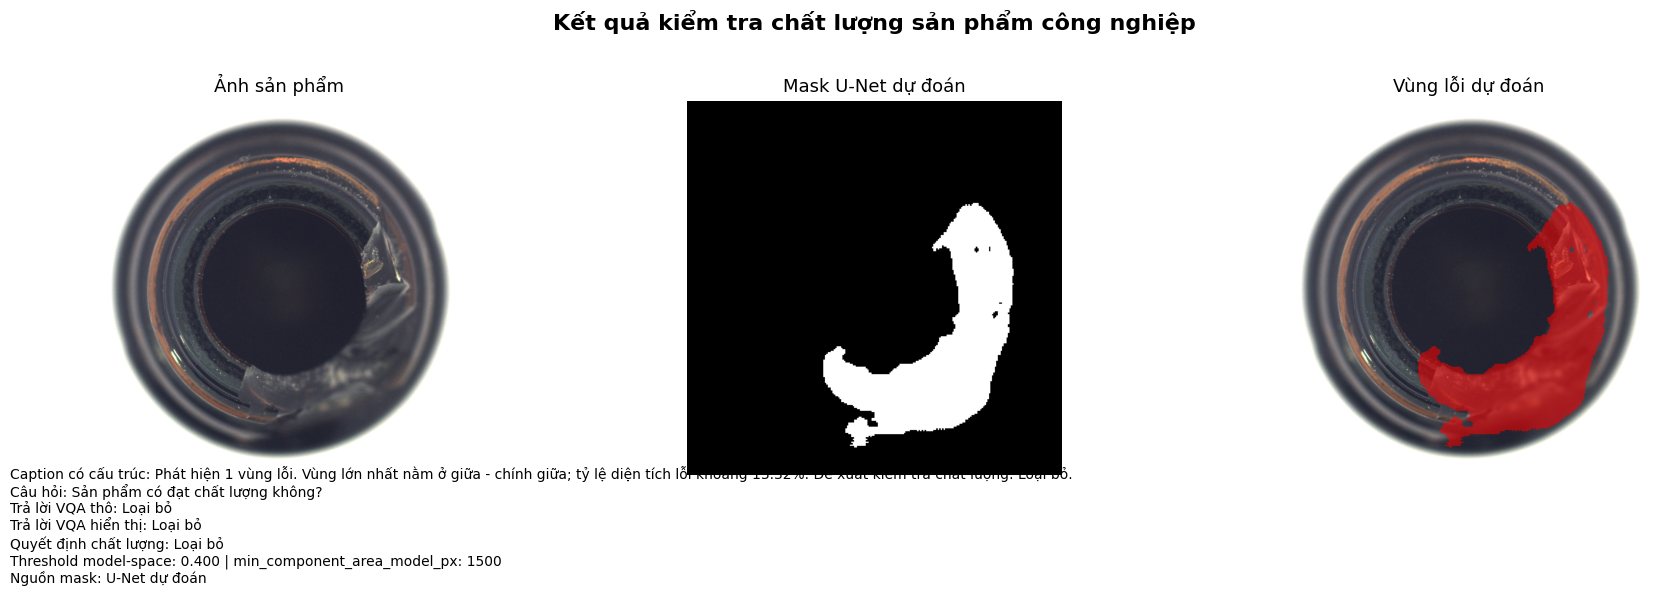

Kết quả broken_large: Loại bỏ
Nguồn mask: unet_predicted
VQA raw: Loại bỏ
VQA hiển thị: Loại bỏ
Postprocess: model_resolution | min_component_area_model_px= 1500
QUALITY GATE broken_large: PASS

--- QUALITY GATE WEEK04: good ---


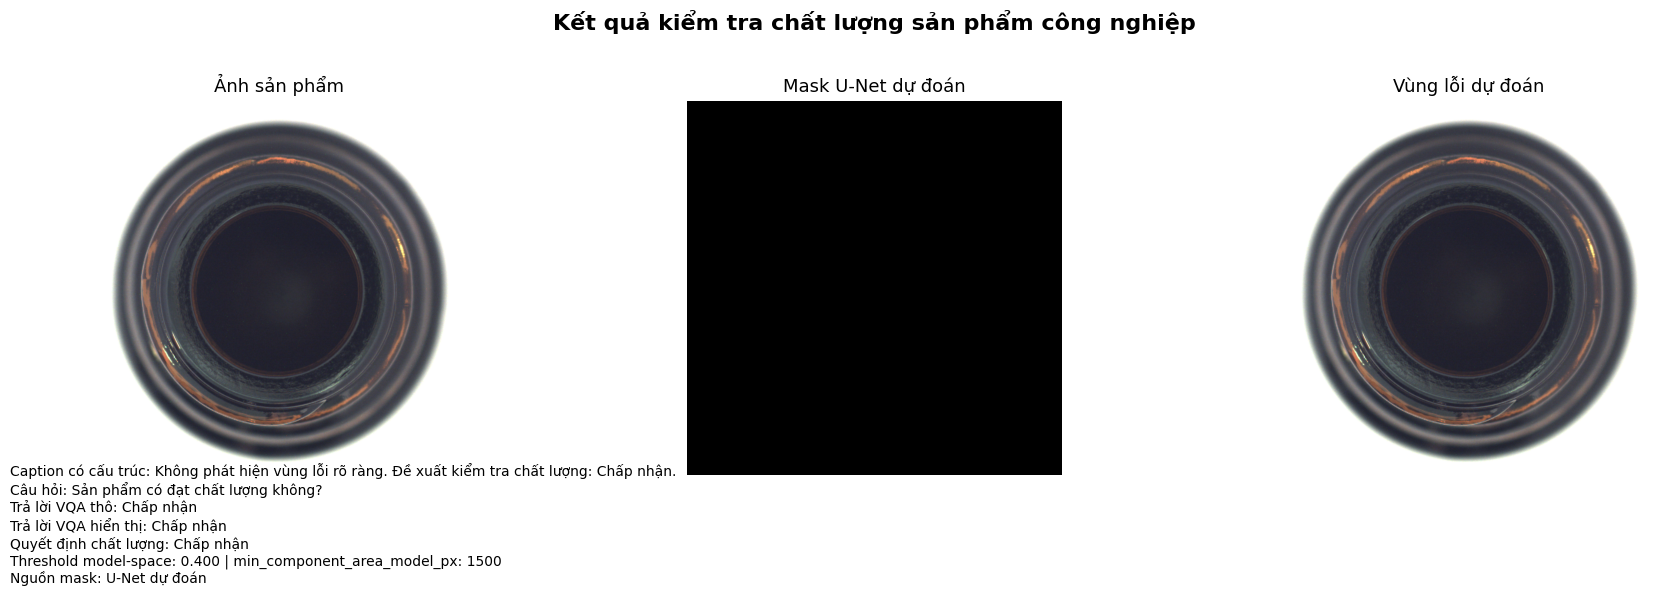

Kết quả good: Chấp nhận
Nguồn mask: unet_predicted
VQA raw: Chấp nhận
VQA hiển thị: Chấp nhận
Postprocess: model_resolution | min_component_area_model_px= 1500
QUALITY GATE good: PASS

--- TỔNG KẾT QUALITY GATE WEEK04 ---
PASS: broken_large -> Loại bỏ; good -> Chấp nhận; VQA hiển thị đồng bộ Quality Decision.


In [17]:
# ==========================================================
# 5. INFERENCE END-TO-END, OUTPUT TIẾNG VIỆT VÀ QUALITY GATE
# ==========================================================
# Chỉ dùng U-Net predicted mask sau postprocess model-space.
# Ground-truth mask không được dùng làm feature, caption, Quality Decision
# hoặc output inference.


from pathlib import Path
import json
import shutil
import unicodedata

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch


_REQUIRED_NAMES = [
    "RESULT_DIR",
    "OUTPUT_DIR",
    "CATEGORY_ROOT",
    "IMAGE_SIZE",
    "HAS_MVTEC",
    "FUSION_CHECKPOINT",
    "predict_unet_mask",
    "mask_features",
    "structured_template_caption",
    "tokenize_vietnamese",
    "load_fusion_model",
    "load_unet_model",
    "load_week03_postprocess_config",
]

_missing_names = [
    name
    for name in _REQUIRED_NAMES
    if name not in globals()
]

if _missing_names:
    raise RuntimeError(
        "Thiếu biến hoặc hàm từ các cell trước: "
        + ", ".join(_missing_names)
        + ". Hãy Restart Kernel rồi Run All từ đầu."
    )

RESULT_DIR = Path(RESULT_DIR)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Ép Cell Quality Gate dùng checkpoint/config đã resolve ở Cell 0.1.
# Không phụ thuộc vào biến cũ còn giữ trong kernel của lần chạy trước.
load_unet_model()
_WEEK03_CONFIG_FOR_GATE = load_week03_postprocess_config()

MAX_QUESTION_LENGTH = int(
    globals().get("MAX_QUESTION_LENGTH", 16)
)


def normalize_text(text: str) -> str:
    """Chuẩn hóa tiếng Việt, bao gồm chuyển đ thành d."""
    normalized = str(text).replace("Đ", "D").replace("đ", "d")
    normalized = unicodedata.normalize("NFD", normalized)

    normalized = "".join(
        char
        for char in normalized
        if unicodedata.category(char) != "Mn"
    )

    return normalized.lower().strip()


def is_quality_question(question: str) -> bool:
    normalized = normalize_text(question)

    patterns = [
        "san pham co dat chat luong khong",
        "san pham co dat khong",
        "co chap nhan san pham khong",
        "san pham co dat tieu chuan khong",
        "is the product acceptable",
        "is this product acceptable",
    ]

    return any(pattern in normalized for pattern in patterns)


# Unit checks: nếu lỗi normalize tiếng Việt thì dừng ngay.
assert is_quality_question("Sản phẩm có đạt chất lượng không?")
assert is_quality_question("Sản phẩm có đạt chất lượng không ?")
assert is_quality_question("San pham co dat chat luong khong?")
assert not is_quality_question("Vùng lỗi nằm ở vị trí nào?")


def safe_prefix(prefix: str, image_path: Path) -> str:
    clean_prefix = str(prefix).strip()

    if not clean_prefix:
        clean_prefix = f"{image_path.parent.name}_{image_path.stem}"

    return (
        clean_prefix
        .replace(" ", "_")
        .replace("/", "_")
        .replace("\\", "_")
    )


def ensure_binary_mask(mask: np.ndarray) -> np.ndarray:
    if mask is None:
        raise ValueError("U-Net không trả về mask.")

    mask = np.asarray(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"Mask phải có 2 chiều, nhận được shape={mask.shape}."
        )

    return (mask > 0).astype(np.uint8)


def create_overlay(
    image_rgb: np.ndarray,
    mask: np.ndarray,
    alpha: float = 0.55,
) -> np.ndarray:
    overlay = image_rgb.astype(np.float32).copy()
    defect_pixels = mask > 0

    red_layer = np.zeros_like(overlay)
    red_layer[..., 0] = 255

    overlay[defect_pixels] = (
        (1.0 - alpha) * overlay[defect_pixels]
        + alpha * red_layer[defect_pixels]
    )

    return overlay.astype(np.uint8)


def answer_from_vocab(answer_vocab, answer_id: int) -> str:
    """Giải mã answer id cho checkpoint lưu answer_vocab dạng list hoặc dict."""
    if isinstance(answer_vocab, (list, tuple)):
        if 0 <= answer_id < len(answer_vocab):
            return str(answer_vocab[answer_id])
        return "Không xác định"

    if isinstance(answer_vocab, dict):
        # Kiểu 1: id -> answer.
        if answer_id in answer_vocab:
            return str(answer_vocab[answer_id])

        if str(answer_id) in answer_vocab:
            return str(answer_vocab[str(answer_id)])

        # Kiểu 2: answer -> id.
        for answer, index in answer_vocab.items():
            try:
                if int(index) == answer_id:
                    return str(answer)
            except (TypeError, ValueError):
                continue

    return "Không xác định"


def answer_index_from_vocab(answer_vocab, answer_text: str) -> int | None:
    """
    Tìm answer index cho checkpoint lưu answer_vocab dạng list/tuple hoặc dict.

    Không gọi answer_vocab.get() trực tiếp vì checkpoint hiện tại lưu list.
    """
    target = str(answer_text)

    if isinstance(answer_vocab, (list, tuple)):
        for index, answer in enumerate(answer_vocab):
            if str(answer) == target:
                return index
        return None

    if isinstance(answer_vocab, dict):
        # Kiểu 1: answer -> id.
        if target in answer_vocab:
            try:
                return int(answer_vocab[target])
            except (TypeError, ValueError):
                return None

        # Kiểu 2: id -> answer.
        for key, value in answer_vocab.items():
            if str(value) == target:
                try:
                    return int(key)
                except (TypeError, ValueError):
                    return None

    return None


def question_answer_candidates(question: str) -> list[str]:
    """
    Trả về tập đáp án hợp lệ theo loại câu hỏi.
    Dùng normalize_text để vẫn hoạt động với dấu câu hoặc tiếng Việt không dấu.
    """
    normalized = normalize_text(question)

    if (
        "co loi be mat" in normalized
        or "co loi khong" in normalized
    ):
        return [
            "Có lỗi bề mặt",
            "Không phát hiện lỗi",
        ]

    if (
        "dat chat luong" in normalized
        or "co dat khong" in normalized
        or "can loai bo" in normalized
        or "chap nhan san pham" in normalized
    ):
        return [
            "Chấp nhận",
            "Loại bỏ",
        ]

    if "vi tri" in normalized:
        return [
            "Không có vị trí lỗi",
            "phía trên - bên trái",
            "phía trên - chính giữa",
            "phía trên - bên phải",
            "ở giữa - bên trái",
            "ở giữa - chính giữa",
            "ở giữa - bên phải",
            "phía dưới - bên trái",
            "phía dưới - chính giữa",
            "phía dưới - bên phải",
        ]

    if "dien tich" in normalized:
        return [
            "Diện tích lỗi lớn",
            "Diện tích lỗi nhỏ",
        ]

    if "bao nhieu vung loi" in normalized:
        return [
            "Không có vùng lỗi",
            "Một vùng lỗi",
            "Nhiều vùng lỗi",
        ]

    return []


def constrained_answer_indices(answer_vocab, question: str) -> list[int]:
    """
    Chuyển đáp án hợp lệ thành các index trong checkpoint answer_vocab.
    Báo lỗi rõ nếu checkpoint thiếu toàn bộ đáp án của loại câu hỏi đang dùng.
    """
    candidates = question_answer_candidates(question)

    if not candidates:
        return []

    indices = []

    for candidate in candidates:
        index = answer_index_from_vocab(answer_vocab, candidate)

        if index is not None:
            indices.append(index)

    indices = sorted(set(indices))

    if not indices:
        raise RuntimeError(
            "Checkpoint Fusion không chứa đáp án phù hợp cho câu hỏi: "
            f"{question!r}. Đáp án cần có: {candidates}"
        )

    return indices


def predict_vqa_answer(
    image_path: str,
    question: str,
    detection_features,
    segmentation_features,
) -> str:
    """Dự đoán raw answer từ Fusion VQA với constrained decoding."""
    loaded = load_fusion_model()

    if loaded is None:
        raise RuntimeError(
            "Chưa có checkpoint Fusion VQA đã huấn luyện."
        )

    model, question_vocab, answer_vocab, device = loaded

    image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(f"Không đọc được ảnh: {image_path}")

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )

    image_rgb = cv2.resize(
        image_rgb,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA,
    )

    token_ids = [
        question_vocab.get(token, 1)
        for token in tokenize_vietnamese(question)
    ]

    token_ids = (
        token_ids + [0] * MAX_QUESTION_LENGTH
    )[:MAX_QUESTION_LENGTH]

    image_tensor = (
        torch.from_numpy(image_rgb.transpose(2, 0, 1))
        .float()
        .unsqueeze(0)
        .to(device)
        / 255.0
    )

    question_tensor = torch.tensor(
        [token_ids],
        dtype=torch.long,
        device=device,
    )

    detection_tensor = torch.tensor(
        [np.asarray(detection_features, dtype=np.float32)],
        dtype=torch.float32,
        device=device,
    )

    segmentation_tensor = torch.tensor(
        [np.asarray(segmentation_features, dtype=np.float32)],
        dtype=torch.float32,
        device=device,
    )

    with torch.inference_mode():
        logits = model(
            image_tensor,
            question_tensor,
            detection_tensor,
            segmentation_tensor,
        )

    valid_indices = constrained_answer_indices(
        answer_vocab,
        question,
    )

    if valid_indices:
        valid_mask = torch.zeros(
            logits.size(1),
            dtype=torch.bool,
            device=device,
        )
        valid_mask[valid_indices] = True
        logits = logits.masked_fill(~valid_mask, -1e9)

    answer_id = int(logits.argmax(dim=1).item())

    return answer_from_vocab(answer_vocab, answer_id)


def make_structured_caption(mask: np.ndarray) -> str:
    caption = str(structured_template_caption(mask)).strip()

    if caption.lower().startswith("caption có cấu trúc"):
        return caption

    return f"Caption có cấu trúc: {caption}"


def save_final_output(
    image_path: str,
    mask: np.ndarray,
    result: dict,
    prefix: str = "",
    save_canonical_file: bool = False,
) -> Path:
    source_path = Path(image_path)

    image_bgr = cv2.imread(str(source_path), cv2.IMREAD_COLOR)

    if image_bgr is None:
        raise ValueError(
            f"Không đọc được ảnh để lưu output: {source_path}"
        )

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB,
    )

    mask = ensure_binary_mask(mask)

    if mask.shape != image_rgb.shape[:2]:
        mask = cv2.resize(
            mask,
            (image_rgb.shape[1], image_rgb.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )

    overlay = create_overlay(image_rgb, mask)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    panels = [
        (image_rgb, "Ảnh sản phẩm"),
        (mask, "Mask U-Net dự đoán"),
        (overlay, "Vùng lỗi dự đoán"),
    ]

    for ax, (content, title) in zip(axes, panels):
        ax.imshow(
            content,
            cmap="gray" if content.ndim == 2 else None,
        )
        ax.set_title(title, fontsize=13)
        ax.axis("off")

    summary = (
        f"{result['caption']}\n"
        f"Câu hỏi: {result['question']}\n"
        f"Trả lời VQA thô: {result['vqa_answer_raw']}\n"
        f"Trả lời VQA hiển thị: {result['vqa_answer']}\n"
        f"Quyết định chất lượng: {result['quality_decision']}\n"
        f"Threshold model-space: {result['mask_threshold']:.3f} | "
        f"min_component_area_model_px: "
        f"{result['min_component_area_model_px']}\n"
        "Nguồn mask: U-Net dự đoán"
    )

    fig.suptitle(
        "Kết quả kiểm tra chất lượng sản phẩm công nghiệp",
        fontsize=16,
        fontweight="bold",
    )

    fig.text(
        0.02,
        0.02,
        summary,
        fontsize=10,
        wrap=True,
        va="bottom",
    )

    plt.tight_layout(rect=[0, 0.18, 1, 0.92])

    clean_prefix = safe_prefix(prefix, source_path)

    png_path = RESULT_DIR / (
        f"{clean_prefix}_ket_qua_kiem_tra_tieng_viet.png"
    )

    fig.savefig(
        png_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    if save_canonical_file:
        shutil.copy2(
            png_path,
            RESULT_DIR / "ket_qua_kiem_tra_tieng_viet.png",
        )

    return png_path


def write_result_json(
    result: dict,
    image_path: Path,
    prefix: str = "",
    save_canonical_file: bool = False,
) -> Path:
    clean_prefix = safe_prefix(prefix, image_path)

    json_path = RESULT_DIR / (
        f"{clean_prefix}_ket_qua_kiem_tra_tieng_viet.json"
    )

    json_path.write_text(
        json.dumps(result, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    if save_canonical_file:
        shutil.copy2(
            json_path,
            RESULT_DIR / "ket_qua_kiem_tra_tieng_viet.json",
        )

    return json_path


def inspect_product(
    image_path,
    question: str,
    prefix: str = "",
    save_canonical_file: bool = False,
):
    """
    image -> U-Net predicted mask -> mask-derived features
    -> Fusion raw answer -> segmentation safety gate
    -> caption + JSON + PNG.
    """
    image_path = Path(image_path)

    if not image_path.exists():
        return {"error": f"Không tìm thấy ảnh: {image_path}"}

    mask = ensure_binary_mask(
        predict_unet_mask(str(image_path))
    )

    detection_features, segmentation_features, _ = mask_features(mask)

    detection_features = (
        np.asarray(detection_features, dtype=np.float32)
        .flatten()
        .tolist()
    )

    segmentation_features = (
        np.asarray(segmentation_features, dtype=np.float32)
        .flatten()
        .tolist()
    )

    if len(detection_features) < 7:
        raise RuntimeError(
            "mask_features phải trả về tối thiểu 7 detection features."
        )

    quality_decision = (
        "Loại bỏ"
        if int(detection_features[0]) > 0
        else "Chấp nhận"
    )

    vqa_answer_raw = predict_vqa_answer(
        image_path=str(image_path),
        question=question,
        detection_features=detection_features,
        segmentation_features=segmentation_features,
    )

    if is_quality_question(question):
        vqa_answer = quality_decision
        consistency_rule = "segmentation_safety_gate"
    else:
        vqa_answer = vqa_answer_raw
        consistency_rule = "fusion_raw_answer"

    clean_prefix = safe_prefix(prefix, image_path)

    mask_path = RESULT_DIR / (
        f"{clean_prefix}_mask_unet_du_doan.png"
    )

    cv2.imwrite(
        str(mask_path),
        (mask * 255).astype(np.uint8),
    )

    result = {
        "image_path": str(image_path),
        "question": question,
        "mask_threshold": float(_OPTIMAL_THRESHOLD),
        "min_component_area_model_px": int(
            _MIN_COMPONENT_AREA_MODEL_PX
        ),
        "postprocess_space": "model_resolution",
        "mask_derived_detection_features": {
            "so_vung_loi": int(detection_features[0]),
            "x_vung_lon_nhat": float(detection_features[1]),
            "y_vung_lon_nhat": float(detection_features[2]),
            "rong_vung_lon_nhat": float(detection_features[3]),
            "cao_vung_lon_nhat": float(detection_features[4]),
            "ty_le_dien_tich_loi": float(detection_features[5]),
            "mask_coverage": float(detection_features[6]),
        },
        "segmentation_mask_path": str(mask_path),
        "caption": make_structured_caption(mask),
        "vqa_answer_raw": vqa_answer_raw,
        "vqa_answer": vqa_answer,
        "quality_decision": quality_decision,
        "source_of_mask": "unet_predicted",
        "vqa_consistency_rule": consistency_rule,
    }

    png_path = save_final_output(
        image_path=str(image_path),
        mask=mask,
        result=result,
        prefix=clean_prefix,
        save_canonical_file=save_canonical_file,
    )

    json_path = write_result_json(
        result=result,
        image_path=image_path,
        prefix=clean_prefix,
        save_canonical_file=save_canonical_file,
    )

    result["output_png_path"] = str(png_path)
    result["result_json_path"] = str(json_path)

    json_path.write_text(
        json.dumps(result, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    if save_canonical_file:
        shutil.copy2(
            json_path,
            RESULT_DIR / "ket_qua_kiem_tra_tieng_viet.json",
        )

    return result


def report_quality_gate(name: str, result: dict, expected: str) -> bool:
    if "error" in result:
        print(f"QUALITY GATE {name}: ERROR")
        print(result["error"])
        return False

    decision_ok = result.get("quality_decision") == expected
    answer_ok = result.get("vqa_answer") == expected
    source_ok = result.get("source_of_mask") == "unet_predicted"
    config_ok = (
        result.get("postprocess_space") == "model_resolution"
        and abs(
            float(result.get("mask_threshold", -1.0))
            - float(_WEEK03_CONFIG_FOR_GATE["threshold"])
        ) < 1e-9
        and int(
            result.get("min_component_area_model_px", -1)
        ) == int(
            _WEEK03_CONFIG_FOR_GATE[
                "min_component_area_model_px"
            ]
        )
    )

    print(f"Kết quả {name}: {result.get('quality_decision')}")
    print("Nguồn mask:", result.get("source_of_mask"))
    print("VQA raw:", result.get("vqa_answer_raw"))
    print("VQA hiển thị:", result.get("vqa_answer"))
    print(
        "Postprocess:",
        result.get("postprocess_space"),
        "| min_component_area_model_px=",
        result.get("min_component_area_model_px"),
    )

    passed = decision_ok and answer_ok and source_ok and config_ok

    print(
        f"QUALITY GATE {name}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

    return passed


# ==========================================================
# QUALITY GATE WEEK04: independent images, not in QA split
# ==========================================================

if HAS_MVTEC:
    broken_large_path = (
        CATEGORY_ROOT / "test" / "broken_large" / "000.png"
    )

    good_path = CATEGORY_ROOT / "test" / "good" / "000.png"

    print("\n--- QUALITY GATE WEEK04: broken_large ---")

    if broken_large_path.exists():
        broken_result = inspect_product(
            image_path=broken_large_path,
            question="Sản phẩm có đạt chất lượng không?",
            prefix="w4_broken_large",
            save_canonical_file=True,
        )

        broken_pass = report_quality_gate(
            "broken_large",
            broken_result,
            expected="Loại bỏ",
        )
    else:
        broken_pass = False
        print("Không tìm thấy:", broken_large_path)

    print("\n--- QUALITY GATE WEEK04: good ---")

    if good_path.exists():
        good_result = inspect_product(
            image_path=good_path,
            question="Sản phẩm có đạt chất lượng không?",
            prefix="w4_good",
            save_canonical_file=False,
        )

        good_pass = report_quality_gate(
            "good",
            good_result,
            expected="Chấp nhận",
        )
    else:
        good_pass = False
        print("Không tìm thấy:", good_path)

    quality_gate_manifest = pd.DataFrame(
        [
            {
                "gate_name": "broken_large",
                "expected_decision": "Loại bỏ",
                "quality_decision": (
                    broken_result.get("quality_decision")
                    if "broken_result" in globals()
                    else ""
                ),
                "vqa_answer": (
                    broken_result.get("vqa_answer")
                    if "broken_result" in globals()
                    else ""
                ),
                "passed": bool(broken_pass),
            },
            {
                "gate_name": "good",
                "expected_decision": "Chấp nhận",
                "quality_decision": (
                    good_result.get("quality_decision")
                    if "good_result" in globals()
                    else ""
                ),
                "vqa_answer": (
                    good_result.get("vqa_answer")
                    if "good_result" in globals()
                    else ""
                ),
                "passed": bool(good_pass),
            },
        ]
    )

    quality_gate_manifest.to_csv(
        OUTPUT_DIR / "quality_gate_manifest_week04.csv",
        index=False,
    )

    print("\n--- TỔNG KẾT QUALITY GATE WEEK04 ---")

    if broken_pass and good_pass:
        print(
            "PASS: broken_large -> Loại bỏ; "
            "good -> Chấp nhận; "
            "VQA hiển thị đồng bộ Quality Decision."
        )
    else:
        print(
            "FAIL: Không dùng output Week04 làm kết quả cuối. "
            "Kiểm tra lại Week03 config, QA split và postprocess model-space."
        )

else:
    print(
        "Chưa có MVTec AD bottle. "
        "Không thể chạy Quality Gate Week04."
    )


In [18]:
ALLOW_MODEL_DOWNLOAD = False

if ALLOW_MODEL_DOWNLOAD:
    print("Bạn có thể cài/khởi tạo BLIP hoặc CLIP tại đây khi Kaggle Internet đã được bật.")
    print("Không tự động tải model trong notebook mặc định.")
else:
    print("Đang dùng structured template caption tiếng Việt. BLIP/CLIP là tùy chọn, hiện tắt.")


Đang dùng structured template caption tiếng Việt. BLIP/CLIP là tùy chọn, hiện tắt.
